# Medication block EDA (Paulo)

Scope: the 23 drug columns (`metformin` → `metformin-pioglitazone`) + `readmitted`.

## Step 1 — Load & sanity check

Load with `na_values="?"` and `keep_default_na=False`, confirm the 101,766 × 50 shape, and check the value counts of the drug columns.

In [1]:
import pandas as pd

# keep_default_na=False so the text "None" (test not done) is not read as NaN
df = pd.read_csv("../data/raw/diabetic_data.csv", na_values="?", keep_default_na=False, low_memory=False)
assert df.shape == (101766, 50), df.shape
print("shape:", df.shape)
print("encounters:", df["encounter_id"].nunique(), "| patients:", df["patient_nbr"].nunique())

shape: (101766, 50)
encounters: 101766 | patients: 71518


In [2]:
drug_cols = df.loc[:, "metformin":"metformin-pioglitazone"].columns.tolist()
assert len(drug_cols) == 23
print("levels found in drug columns:", sorted(pd.unique(df[drug_cols].values.ravel())))
print("missing values in drug columns:", df[drug_cols].isna().sum().sum())

levels found in drug columns: ['Down', 'No', 'Steady', 'Up']


missing values in drug columns: 0


In [3]:
# Value counts per drug, one row per drug, ordered by number of encounters taking it
counts = (
    df[drug_cols].apply(lambda s: s.value_counts()).T
    .reindex(columns=["No", "Steady", "Up", "Down"]).fillna(0).astype(int)
)
counts["taking"] = counts[["Steady", "Up", "Down"]].sum(axis=1)
counts.sort_values("taking", ascending=False)

,No,Steady,Up,Down,taking
insulin,47383,30849,11316,12218,54383
metformin,81778,18346,1067,575,19988
glipizide,89080,11356,770,560,12686
glyburide,91116,9274,812,564,10650
pioglitazone,94438,6976,234,118,7328
rosiglitazone,95401,6100,178,87,6365
glimepiride,96575,4670,327,194,5191
repaglinide,100227,1384,110,45,1539
glyburide-metformin,101060,692,8,6,706
nateglinide,101063,668,24,11,703


In [4]:
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

### Step 1 — notes

- **Load is clean:** 101,766 encounters × 50 columns, 71,518 unique patients, as documented. The comma separator and `keep_default_na=False` are correct; `low_memory=False` removes the mixed-type warning on `payer_code`.
- **Drug columns are tidy:** all 23 use only `No` / `Steady` / `Up` / `Down` and have no missing values, so they need no cleaning.
- **Usage is very uneven:** insulin is used in 54,383 encounters and metformin in 19,988, while 9 drugs have fewer than 40 users and `examide` / `citoglipton` have none. Target: `<30` = 11,357 encounters (11.2%).

## Step 2 — Profile the medication block

`ydata-profiling` on the drug columns + `readmitted` only. Report saved to `reports/generated/`.

In [5]:
from ydata_profiling import ProfileReport

C:\Users\felic\AppData\Local\Temp\ipykernel_47784\44057814.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [6]:
med = df[drug_cols + ["readmitted"]]

In [7]:
profile = ProfileReport(med, title="Medication block — diabetic_data", explorative=True)
profile.to_file("../reports/generated/profile-report-medications.html")

C:\Users\felic\OneDrive\Documentos\NOVA IMS\2 - Semester\Enterprise Data Science Bootcamp\Project\enterprise-data-science-bootcamp\.venv\Lib\site-packages\ydata_profiling\utils\dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

  4%|▍         | 1/24 [00:01<00:23,  1.02s/it]

  8%|▊         | 2/24 [00:01<00:12,  1.82it/s]

 12%|█▎        | 3/24 [00:01<00:09,  2.29it/s]

... (4 outputs left out)

100%|██████████| 24/24 [00:03<00:00,  7.63it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [8]:
# Alerts raised by the profile, grouped by type
alerts = pd.DataFrame(
    [(a.alert_type.name, a.column_name) for a in profile.get_description().alerts],
    columns=["alert", "column"],
)
for alert, cols in alerts.groupby("alert")["column"]:
    print(f"{alert} ({len(cols)}): {list(cols)}")

not_flagged = [c for c in drug_cols if c not in set(alerts["column"])]
print("Drug columns with no alert:", not_flagged)
print("Duplicate rows in this 24-column subset:", med.duplicated().sum())

CONSTANT (2): ['examide', 'citoglipton']
DUPLICATES (1): [None]
IMBALANCE (20): ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
Drug columns with no alert: ['insulin']
Duplicate rows in this 24-column subset: 99559


In [9]:
# Same picture as numbers: share of the most frequent level and number of encounters taking the drug
summary = pd.DataFrame({
    "n_levels": med[drug_cols].nunique(),
    "top_level": med[drug_cols].mode().iloc[0],
    "top_share_%": (med[drug_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(2),
    "n_taking": (med[drug_cols] != "No").sum(),
    "n_missing": med[drug_cols].isna().sum(),
}).sort_values("n_taking")
summary

,n_levels,top_level,top_share_%,n_taking,n_missing
examide,1,No,100.00,0,0
citoglipton,1,No,100.00,0,0
glimepiride-pioglitazone,2,No,100.00,1,0
acetohexamide,2,No,100.00,1,0
metformin-pioglitazone,2,No,100.00,1,0
metformin-rosiglitazone,2,No,100.00,2,0
troglitazone,2,No,100.00,3,0
glipizide-metformin,2,No,99.99,13,0
tolbutamide,2,No,99.98,23,0
miglitol,4,No,99.96,38,0


In [10]:
med["readmitted"].value_counts(normalize=True).mul(100).round(2)

readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

### Step 2 — notes

- **Zero variance:** `examide` and `citoglipton` are flagged CONSTANT (100% `No`). There is nothing to learn from them, so they are certain drops.
- **High imbalance:** 20 of the 23 drug columns are flagged IMBALANCE. Insulin is the only one with no alert (46.6% `No`). That flag alone isn't enough to drop a column, because metformin (~20k users) is flagged too. Step 3 needs a usage-count threshold. The 7 columns with 3 or fewer users are effectively empty.
- **No missing values** in any drug column. ydata flags 1,185 duplicate rows, and `med.duplicated()` finds 99,559 rows that repeat an earlier pattern. Both are expected with 24 categorical columns, so this is not a data-quality issue. Target in this file: `<30` = 11.16%, `>30` = 34.93%, `NO` = 53.91%.

## Step 3 — Drop list

Rule: keep a drug if at least `THRESHOLD` of encounters take it (value != `"No"`); drop it otherwise, and flag columns with a single value as constant.

In [11]:
THRESHOLD = 0.01  # minimum share of encounters taking the drug

taking = df[drug_cols] != "No"
drop_list = pd.DataFrame({
    "n_levels": df[drug_cols].nunique(),
    "n_taking": taking.sum(),
    "pct_taking": (taking.mean() * 100).round(2),
}).sort_values("n_taking", ascending=False)

drop_list["decision"] = "keep"
drop_list.loc[drop_list["n_taking"] < THRESHOLD * len(df), "decision"] = "drop_rare"
drop_list.loc[drop_list["n_levels"] == 1, "decision"] = "drop_constant"
print(f"Threshold: {THRESHOLD:.0%} of {len(df):,} encounters = {THRESHOLD * len(df):,.0f} encounters")
drop_list

Threshold: 1% of 101,766 encounters = 1,018 encounters


,n_levels,n_taking,pct_taking,decision
insulin,4,54383,53.44,keep
metformin,4,19988,19.64,keep
glipizide,4,12686,12.47,keep
glyburide,4,10650,10.47,keep
pioglitazone,4,7328,7.20,keep
rosiglitazone,4,6365,6.25,keep
glimepiride,4,5191,5.10,keep
repaglinide,4,1539,1.51,keep
glyburide-metformin,4,706,0.69,drop_rare
nateglinide,4,703,0.69,drop_rare


In [12]:
MED_KEEP = drop_list.index[drop_list["decision"] == "keep"].tolist()
MED_DROP = drop_list.index[drop_list["decision"] != "keep"].tolist()
print(f"MED_KEEP = {MED_KEEP}  # {len(MED_KEEP)} columns")
print(f"MED_DROP = {MED_DROP}  # {len(MED_DROP)} columns")

MED_KEEP = ['insulin', 'metformin', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'glimepiride', 'repaglinide']  # 8 columns
MED_DROP = ['glyburide-metformin', 'nateglinide', 'acarbose', 'chlorpropamide', 'tolazamide', 'miglitol', 'tolbutamide', 'glipizide-metformin', 'troglitazone', 'metformin-rosiglitazone', 'acetohexamide', 'glimepiride-pioglitazone', 'metformin-pioglitazone', 'examide', 'citoglipton']  # 15 columns


### Step 3 — notes

- **Rule:** keep a drug if at least 1% of encounters take it (`THRESHOLD = 0.01`, about 1,018 encounters). Below that, a drug is too rare to estimate a reliable readmission rate per level. Columns with a single value are dropped as constant.
- **Result:** 8 kept (`insulin`, `metformin`, `glipizide`, `glyburide`, `pioglitazone`, `rosiglitazone`, `glimepiride`, `repaglinide`) and 15 dropped (13 `drop_rare` + `examide` / `citoglipton` `drop_constant`). The cutoff falls in a clear gap: the smallest kept drug, `repaglinide`, has 1,539 users and the largest dropped one, `glyburide-metformin`, has 706.
- **Open point:** `glyburide-metformin` (706), `nateglinide` (703) and `acarbose` (308) are dropped as individual columns but are not lost entirely, since Step 5's `n_meds_taken` and `n_other_meds` still count them. `MED_KEEP` / `MED_DROP` are lists only: nothing is removed from `df` yet.

## Step 4 — Medication vs target

For each drug in `MED_KEEP`: the <30-day readmission rate by level (`No` / `Steady` / `Up` / `Down`), with a 95% Wilson confidence interval.

A drug gets a chart only if its rate differs across levels in a chi-square test at `ALPHA / len(MED_KEEP)` (Bonferroni, because we test 8 drugs at once).

In [13]:
# ydata-profiling (Step 2) switches matplotlib to the non-interactive "agg" backend; switch back
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

ALPHA = 0.05
LEVELS = ["No", "Steady", "Up", "Down"]
y = (df["readmitted"] == "<30").astype(int)
BASE_RATE = y.mean()


def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n; returns (low, high)."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


rows = []
for drug in MED_KEEP:
    g = y.groupby(df[drug]).agg(n="size", n_lt30="sum").reindex(LEVELS)
    for level, (n, k) in g.iterrows():
        low, high = wilson_ci(k, n)
        rows.append((drug, level, n, k, k / n, low, high))
rates = pd.DataFrame(rows, columns=["drug", "level", "n", "n_lt30", "rate", "ci_low", "ci_high"])

print(f"Base <30 rate: {BASE_RATE:.2%}")
# Rate (%) by level, with group sizes alongside
wide = rates.pivot(index="drug", columns="level", values="rate").loc[MED_KEEP, LEVELS].mul(100).round(1)
sizes = rates.pivot(index="drug", columns="level", values="n").loc[MED_KEEP, LEVELS].add_prefix("n_")
wide.join(sizes)

Base <30 rate: 11.16%


level,No,Steady,Up,Down,n_No,n_Steady,n_Up,n_Down
drug,,,,,,,,
insulin,10.0,11.1,13.0,13.9,47383,30849,11316,12218
metformin,11.5,9.7,8.2,12.0,81778,18346,1067,575
glipizide,11.1,11.2,12.9,15.2,89080,11356,770,560
glyburide,11.2,10.7,10.5,9.2,91116,9274,812,564
pioglitazone,11.2,10.4,12.4,15.3,94438,6976,234,118
rosiglitazone,11.2,10.5,10.7,5.7,95401,6100,178,87
glimepiride,11.2,10.0,11.3,12.9,96575,4670,327,194
repaglinide,11.1,13.2,18.2,6.7,100227,1384,110,45


In [14]:
# One chi-square test per drug: does the <30 rate depend on the level?
tests = pd.DataFrame(
    [(d, chi2_contingency(pd.crosstab(df[d], y))[1]) for d in MED_KEEP],
    columns=["drug", "p_value"],
).set_index("drug")
tests["rate_taking_%"] = [y[df[d] != "No"].mean() * 100 for d in tests.index]
tests["rate_not_taking_%"] = [y[df[d] == "No"].mean() * 100 for d in tests.index]
tests["chart"] = tests["p_value"] < ALPHA / len(MED_KEEP)
print(f"Bonferroni cut-off: p < {ALPHA / len(MED_KEEP):.4f}")
tests.sort_values("p_value").round({"rate_taking_%": 1, "rate_not_taking_%": 1}).style.format({"p_value": "{:.1e}"})

Bonferroni cut-off: p < 0.0063


,p_value,rate_taking_%,rate_not_taking_%,chart
drug,,,,
insulin,4.0e-41,12.100000,10.000000,True
metformin,1.1e-12,9.700000,11.500000,True
repaglinide,7.3e-03,13.300000,11.100000,False
glipizide,9.3e-03,11.400000,11.100000,False
glimepiride,7.3e-02,10.200000,11.200000,False
pioglitazone,9.4e-02,10.600000,11.200000,False
rosiglitazone,1.4e-01,10.400000,11.200000,False
glyburide,2.0e-01,10.600000,11.200000,False


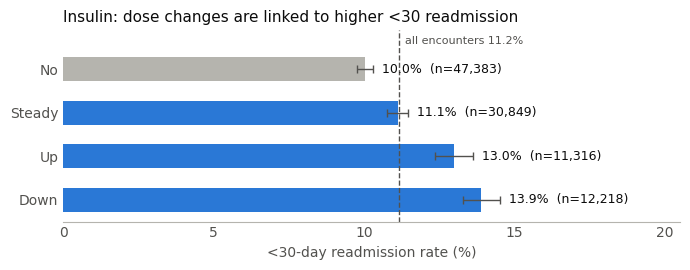

In [15]:
BAR, CONTEXT, INK, MUTED = "#2a78d6", "#b5b4ae", "#0b0b0b", "#52514e"


def plot_drug_rates(drug, title):
    """Horizontal bar chart of the <30 rate by level for one drug, with 95% CIs and the base rate."""
    d = rates[rates["drug"] == drug].set_index("level").loc[LEVELS[::-1]]
    fig, ax = plt.subplots(figsize=(7, 2.8))
    colors = [CONTEXT if lvl == "No" else BAR for lvl in d.index]
    ax.barh(d.index, d["rate"] * 100, height=0.55, color=colors)
    ax.errorbar(d["rate"] * 100, d.index,
                xerr=[(d["rate"] - d["ci_low"]) * 100, (d["ci_high"] - d["rate"]) * 100],
                fmt="none", ecolor=MUTED, elinewidth=1, capsize=3)
    for lvl, r in d.iterrows():
        ax.text(r["ci_high"] * 100 + 0.3, lvl, f"{r['rate']:.1%}  (n={r['n']:,.0f})",
                va="center", fontsize=9, color=INK)
    ax.axvline(BASE_RATE * 100, color=MUTED, linestyle="--", linewidth=1)
    ax.set_ylim(-0.5, len(d) - 0.1)  # headroom above the top bar for the base-rate label
    ax.text(BASE_RATE * 100 + 0.2, len(d) - 0.35, f"all encounters {BASE_RATE:.1%}",
            ha="left", va="center", fontsize=8, color=MUTED)
    ax.set_xlim(0, max(d["ci_high"]) * 100 + 6)
    ax.xaxis.set_major_locator(plt.MultipleLocator(5))
    ax.set_xlabel("<30-day readmission rate (%)", color=MUTED)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.tick_params(colors=MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(CONTEXT)
    plt.tight_layout()
    plt.show()


plot_drug_rates("insulin", "Insulin: dose changes are linked to higher <30 readmission")

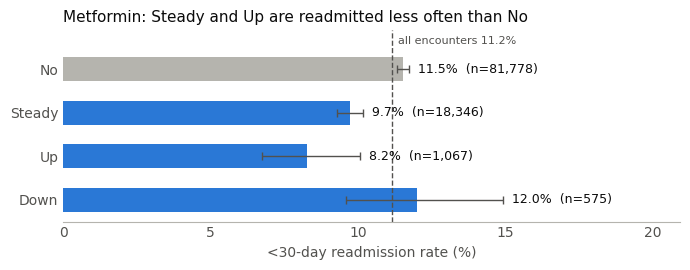

In [16]:
plot_drug_rates("metformin", "Metformin: Steady and Up are readmitted less often than No")

In [17]:
# Sensitivity check: drop expired/hospice discharges (they cannot be readmitted) and recompute.
# Works on a filtered copy; df, y and rates are left unchanged.
EXPIRED_HOSPICE_IDS = [11, 13, 14, 19, 20, 21]  # discharge_disposition_id
expired = df["discharge_disposition_id"].isin(EXPIRED_HOSPICE_IDS)
df_alive = df.loc[~expired].copy()
y_alive = y[~expired]

print(f"Removed: {expired.sum():,} encounters ({expired.mean():.1%}), <30 rate among them: {y[expired].mean():.2%}")
print(f"Base <30 rate: {BASE_RATE:.2%} original -> {y_alive.mean():.2%} without")

sens = []
for drug in ["insulin", "metformin"]:
    original = rates[rates["drug"] == drug].set_index("level")["rate"]
    without = y_alive.groupby(df_alive[drug]).mean()
    for level in LEVELS:
        sens.append((drug, level, original[level] * 100, without[level] * 100))
sensitivity = pd.DataFrame(sens, columns=["drug", "level", "original %", "without %"]).set_index("drug").round(2)
sensitivity

Removed: 2,423 encounters (2.4%), <30 rate among them: 1.77%
Base <30 rate: 11.16% original -> 11.39% without


,level,original %,without %
drug,,,
insulin,No,10.04,10.21
insulin,Steady,11.13,11.37
insulin,Up,12.99,13.33
insulin,Down,13.90,14.22
metformin,No,11.52,11.79
metformin,Steady,9.71,9.78
metformin,Up,8.25,8.28
metformin,Down,12.00,12.02


### Step 4 — notes

- **Insulin is the strongest signal** (p = 4e-41). The <30 rate rises from 10.0% (`No`) to 11.1% (`Steady`), 13.0% (`Up`) and 13.9% (`Down`). Any dose change carries about +3 pp over not taking insulin, which supports `on_insulin_only` and `n_dose_changes` in Step 5. No separate insulin-status feature is needed: the raw `insulin` column already holds it (`No` / `Steady` / `Up` / `Down`).
- **Metformin goes the other way** (p = 1e-12): `Steady` 9.7% and `Up` 8.2% vs 11.5% for `No`. This is probably confounding, not a protective effect: metformin is usually withheld from sicker patients (kidney or heart failure), who are readmitted more anyway. Say so in the presentation.
- **The other 6 drugs don't pass the Bonferroni cut-off** (p < 0.0063). `repaglinide` (p = 0.007) and `glipizide` (p = 0.009) come close, but their striking rates (repaglinide `Up` 18.2%, glipizide `Down` 15.2%) sit on groups of fewer than 800 encounters with wide intervals. They stay in `MED_KEEP` as columns but get no chart.
- **Caveat:** the tests treat the 101,766 encounters as independent, but they come from 71,518 patients, so the p-values are optimistic. The ranking (insulin, then metformin, then the rest) is what matters here.
- Expired/hospice discharges not yet removed; re-checked without them (sensitivity cell) and the patterns hold. Insulin rates move up ~0.2–0.3 pp; metformin users barely change (≤0.07 pp), so metformin's gap to `No` widens slightly.

## Step 5 — Engineered medication features

- `n_meds_taken`: number of the 23 drug columns not `No`
- `n_dose_changes`: number of the 23 drug columns at `Up` or `Down`
- `n_other_meds`: number of `MED_DROP` drugs taken, so the dropped drugs still count
- `on_insulin_only`: insulin taken and no other diabetes drug

Count features are binned 0 / 1 / 2 / 3+. Each feature gets a chi-square test; only those with p < `ALPHA / 4` (Bonferroni over 4 features) get a chart.

In [18]:
def build_med_features(df):
    """Build engineered medication features from the 23 drug columns.

    Returns a new DataFrame with the same index as df (df itself is not modified):
    - n_meds_taken: how many of the 23 drug columns are not "No" (any use: Steady, Up or Down).
    - n_dose_changes: how many of the 23 drug columns are "Up" or "Down" (dose changed this encounter).
    - n_other_meds: how many of the MED_DROP drugs are not "No"; keeps the rare drugs
      dropped in Step 3 in the data as a count.
    - on_insulin_only: True when insulin is not "No" and no other drug column is taken.

    Uses the globals drug_cols (Step 1) and MED_DROP (Step 3).
    """
    taking = df[drug_cols] != "No"
    feats = pd.DataFrame(index=df.index)
    feats["n_meds_taken"] = taking.sum(axis=1)
    feats["n_dose_changes"] = df[drug_cols].isin(["Up", "Down"]).sum(axis=1)
    feats["n_other_meds"] = taking[MED_DROP].sum(axis=1)
    feats["on_insulin_only"] = taking["insulin"] & (taking.drop(columns="insulin").sum(axis=1) == 0)
    return feats


COUNT_FEATURES = ["n_meds_taken", "n_dose_changes", "n_other_meds"]
FEATURES = COUNT_FEATURES + ["on_insulin_only"]
feats = build_med_features(df)

# Binned version: counts as 0 / 1 / 2 / 3+, the flag as No / Yes
binned = pd.DataFrame(index=df.index)
for f in COUNT_FEATURES:
    binned[f] = feats[f].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
binned["on_insulin_only"] = feats["on_insulin_only"].map({False: "No", True: "Yes"})
BIN_ORDER = {f: ["0", "1", "2", "3+"] for f in COUNT_FEATURES} | {"on_insulin_only": ["No", "Yes"]}

for f in COUNT_FEATURES:
    print(f"{f} (raw):", feats[f].value_counts().sort_index().to_dict())

pd.concat(
    {f: binned[f].value_counts().reindex(BIN_ORDER[f]).dropna().astype(int) for f in FEATURES},
    names=["feature", "bin"],
).to_frame("n")

n_meds_taken (raw): {0: 23403, 1: 47314, 2: 21873, 3: 7778, 4: 1335, 5: 58, 6: 5}
n_dose_changes (raw): {0: 74063, 1: 26272, 2: 1318, 3: 108, 4: 5}
n_other_meds (raw): {0: 99856, 1: 1896, 2: 14}


n
feature         bin       
n_meds_taken    0    23403
                1    47314
                2    21873
                3+    9176
n_dose_changes  0    74063
                1    26272
                2     1318
                3+     113
n_other_meds    0    99856
                1     1896
                2       14
on_insulin_only No   70801
                Yes  30965

In [19]:
# <30 rate per bin with 95% Wilson CI, and one chi-square test per feature
rows, tests_5 = [], []
for f in FEATURES:
    g = y.groupby(binned[f]).agg(n="size", n_lt30="sum").reindex(BIN_ORDER[f]).dropna()
    for b, (n, k) in g.iterrows():
        low, high = wilson_ci(k, n)
        rows.append((f, b, int(n), int(k), k / n, low, high))
    tests_5.append((f, chi2_contingency(pd.crosstab(binned[f], y))[1]))

feat_rates = pd.DataFrame(rows, columns=["feature", "bin", "n", "n_lt30", "rate", "ci_low", "ci_high"])
tests_5 = pd.DataFrame(tests_5, columns=["feature", "p_value"]).set_index("feature")
tests_5["chart"] = tests_5["p_value"] < ALPHA / len(FEATURES)

print(f"Base <30 rate: {BASE_RATE:.2%} | Bonferroni cut-off: p < {ALPHA / len(FEATURES):.4f}")
display(tests_5.style.format({"p_value": "{:.1e}"}))
pct = feat_rates.set_index(["feature", "bin"])
pct[["rate", "ci_low", "ci_high"]] = (pct[["rate", "ci_low", "ci_high"]] * 100).round(1)
pct.rename(columns={"rate": "rate %", "ci_low": "ci_low %", "ci_high": "ci_high %"})

Base <30 rate: 11.16% | Bonferroni cut-off: p < 0.0125


,p_value,chart
feature,,
n_meds_taken,8.3e-28,True
n_dose_changes,2.7e-30,True
n_other_meds,2.1e-01,False
on_insulin_only,5.8e-32,True


n  n_lt30  rate %  ci_low %  ci_high %
feature         bin                                            
n_meds_taken    0    23403    2246     9.6       9.2       10.0
                1    47314    5816    12.3      12.0       12.6
                2    21873    2345    10.7      10.3       11.1
                3+    9176     950    10.4       9.7       11.0
n_dose_changes  0    74063    7738    10.4      10.2       10.7
                1    26272    3444    13.1      12.7       13.5
                2     1318     159    12.1      10.4       13.9
                3+     113      16    14.2       8.9       21.8
n_other_meds    0    99856   11160    11.2      11.0       11.4
                1     1896     194    10.2       8.9       11.7
                2       14       3    21.4       7.6       47.6
on_insulin_only No   70801    7357    10.4      10.2       10.6
                Yes  30965    4000    12.9      12.5       13.3

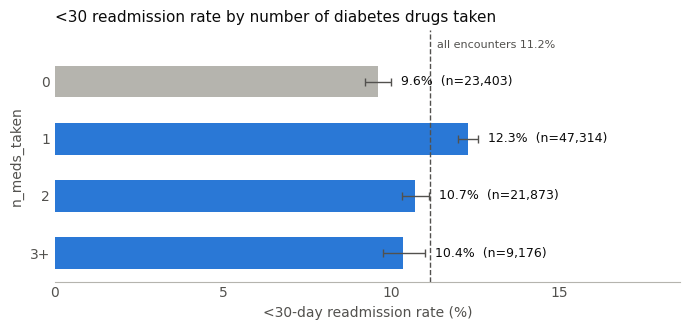

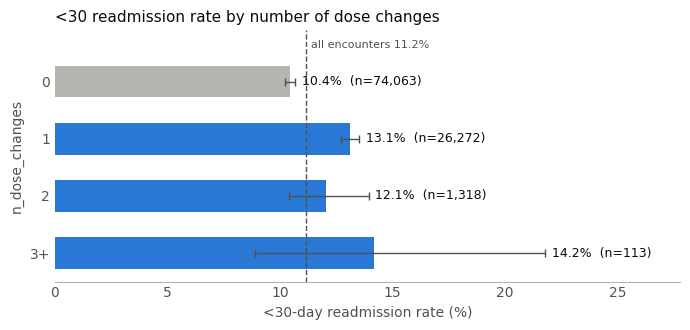

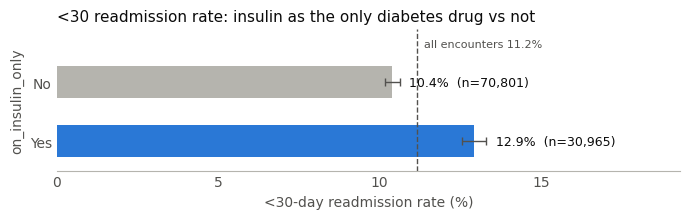

In [20]:
def plot_feature_rates(feature, title):
    """Step 4 chart style for an engineered feature: <30 rate by bin, 95% CIs, base rate line.

    The first bin (0 or No) is the grey reference group.
    """
    d = feat_rates[feat_rates["feature"] == feature].set_index("bin")
    order = [b for b in BIN_ORDER[feature] if b in d.index]
    d = d.loc[order[::-1]]
    fig, ax = plt.subplots(figsize=(7, 0.55 * len(d) + 1.2))
    colors = [CONTEXT if b == order[0] else BAR for b in d.index]
    ax.barh(d.index, d["rate"] * 100, height=0.55, color=colors)
    ax.errorbar(d["rate"] * 100, d.index,
                xerr=[(d["rate"] - d["ci_low"]) * 100, (d["ci_high"] - d["rate"]) * 100],
                fmt="none", ecolor=MUTED, elinewidth=1, capsize=3)
    for b, r in d.iterrows():
        ax.text(r["ci_high"] * 100 + 0.3, b, f"{r['rate']:.1%}  (n={r['n']:,.0f})",
                va="center", fontsize=9, color=INK)
    ax.axvline(BASE_RATE * 100, color=MUTED, linestyle="--", linewidth=1)
    ax.set_ylim(-0.5, len(d) - 0.1)  # headroom above the top bar for the base-rate label
    ax.text(BASE_RATE * 100 + 0.2, len(d) - 0.35, f"all encounters {BASE_RATE:.1%}",
            ha="left", va="center", fontsize=8, color=MUTED)
    ax.set_xlim(0, max(d["ci_high"]) * 100 + 6)
    ax.xaxis.set_major_locator(plt.MultipleLocator(5))
    ax.set_xlabel("<30-day readmission rate (%)", color=MUTED)
    ax.set_ylabel(feature, color=MUTED)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.tick_params(colors=MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(CONTEXT)
    plt.tight_layout()
    plt.show()


FEATURE_TITLES = {
    "n_meds_taken": "<30 readmission rate by number of diabetes drugs taken",
    "n_dose_changes": "<30 readmission rate by number of dose changes",
    "n_other_meds": "<30 readmission rate by number of rare (dropped) drugs taken",
    "on_insulin_only": "<30 readmission rate: insulin as the only diabetes drug vs not",
}
for f in tests_5.index[tests_5["chart"]]:
    plot_feature_rates(f, FEATURE_TITLES[f])

In [21]:
# Cross-check: any Up/Down dose change vs Sofia's `change` column ("Ch" = medication changed)
dose_changed = feats["n_dose_changes"].gt(0).map({False: "no Up/Down", True: "Up/Down >= 1"})
agreement = (feats["n_dose_changes"].gt(0) == df["change"].eq("Ch")).mean()
print(f"Agreement between n_dose_changes > 0 and change == 'Ch': {agreement:.1%}")
pd.crosstab(dose_changed, df["change"], margins=True)

Agreement between n_dose_changes > 0 and change == 'Ch': 81.0%


change,Ch,No,All
n_dose_changes,,,
Up/Down >= 1,27703,0,27703
no Up/Down,19308,54755,74063
All,47011,54755,101766


### Step 5 — notes

- **Dose changes** (`n_dose_changes`, p = 3e-30): 10.4% with no change vs 13.1% with one. The 2 and 3+ bins (12.1%, 14.2%) have wide intervals (n = 1,318 and 113), so the useful contrast is any change vs none. 85% of encounters with a change are insulin `Up` / `Down` (23,534 of 27,703), so this feature overlaps heavily with the raw `insulin` column.
- **Number of drugs is not monotonic** (`n_meds_taken`, p = 8e-28): 9.6% for 0, 12.3% for 1, 10.7% for 2, 10.4% for 3+. The peak at 1 drug matches `on_insulin_only` (p = 6e-32): 30,965 of the 47,314 one-drug encounters are insulin alone, at 12.9% vs 10.4%. Which drug is taken matters more than how many.
- **`n_other_meds` shows no difference** (p = 0.21, no chart): 98% of encounters take none of the dropped drugs, and the 1,896 that take one sit at 10.2% vs 11.2%. This supports the Step 3 drop decision.
- **Cross-check with `change`: 81.0% agreement.** Every encounter with an `Up` / `Down` is `Ch` (0 the other way), but 19,308 `Ch` encounters have no `Up` / `Down`. In the dataset description, `change` also covers a switch of drug (generic name), which the dose levels can't show, so this is a definition difference, not a data error. The two columns are nested, not duplicates: worth telling Sofia.
- **Answers an open point in the main notebook:** Sofia's correlation notes flag `change` and `diabetesMed` (ρ ≈ 0.51) as worth checking for redundancy before modelling. From the drug columns: `diabetesMed == "Yes"` is identical to `n_meds_taken > 0` (100% agreement), and every encounter with an Up/Down is `change == "Ch"`, but `change` also covers switching drugs (81% agreement). So `diabetesMed` is fully explained by the drug columns, while `change` adds information they don't hold.